Total Features: 30
Baseline Accuracy (All Features): 95.61%

Iteration 01/30 | Best Fitness: 0.0407
Iteration 02/30 | Best Fitness: 0.0391
Iteration 03/30 | Best Fitness: 0.0381
Iteration 04/30 | Best Fitness: 0.0377
Iteration 05/30 | Best Fitness: 0.0371
Iteration 06/30 | Best Fitness: 0.0371
Iteration 07/30 | Best Fitness: 0.0367
Iteration 08/30 | Best Fitness: 0.0367
Iteration 09/30 | Best Fitness: 0.0361
Iteration 10/30 | Best Fitness: 0.0361
Iteration 11/30 | Best Fitness: 0.0357
Iteration 12/30 | Best Fitness: 0.0354
Iteration 13/30 | Best Fitness: 0.0354
Iteration 14/30 | Best Fitness: 0.0354
Iteration 15/30 | Best Fitness: 0.0354
Iteration 16/30 | Best Fitness: 0.0354
Iteration 17/30 | Best Fitness: 0.0354
Iteration 18/30 | Best Fitness: 0.0354
Iteration 19/30 | Best Fitness: 0.0354
Iteration 20/30 | Best Fitness: 0.0354
Iteration 21/30 | Best Fitness: 0.0354
Iteration 22/30 | Best Fitness: 0.0354
Iteration 23/30 | Best Fitness: 0.0354
Iteration 24/30 | Best Fitness: 0.0354
Ite

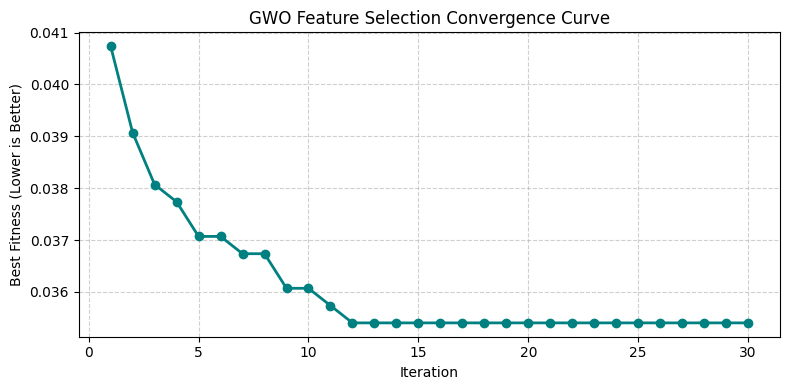

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# ==========================================
# 1. LOAD DATASET & BASELINE MODEL
# ==========================================
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Baseline accuracy using ALL 30 features
baseline_clf = KNeighborsClassifier(n_neighbors=5)
baseline_clf.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline_clf.predict(X_test))

print(f"Total Features: {X.shape[1]}")
print(f"Baseline Accuracy (All Features): {baseline_acc * 100:.2f}%\n")


# ==========================================
# 2. FITNESS FUNCTION
# ==========================================
def calculate_fitness(position, X_train, X_test, y_train, y_test, alpha_w=0.99):
    # Convert continuous values to binary using 0.5 threshold
    binary_mask = (position > 0.5).astype(int)
    selected_count = np.sum(binary_mask)
    total_features = len(position)

    # Penalize heavily if zero features are selected
    if selected_count == 0:
        return 1.0

    # Filter dataset to only include selected columns
    cols = np.where(binary_mask == 1)[0]
    X_train_sub = X_train[:, cols]
    X_test_sub = X_test[:, cols]

    # Train classifier and evaluate accuracy
    clf = KNeighborsClassifier(n_neighbors=5)
    clf.fit(X_train_sub, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_sub))

    # Fitness formula: balance error rate and feature reduction
    fitness = alpha_w * (1.0 - acc) + (1.0 - alpha_w) * (selected_count / total_features)
    return fitness


# ==========================================
# 3. GREY WOLF OPTIMIZER (GWO) ALGORITHM
# ==========================================
def gwo_feature_selection(X_train, X_test, y_train, y_test, num_wolves=15, max_iter=30):
    dim = X_train.shape[1]

    # Initialize Alpha, Beta, and Delta leaders
    Alpha_pos = np.zeros(dim)
    Alpha_score = float("inf")

    Beta_pos = np.zeros(dim)
    Beta_score = float("inf")

    Delta_pos = np.zeros(dim)
    Delta_score = float("inf")

    # Initialize random wolf positions between 0 and 1
    np.random.seed(42)
    positions = np.random.uniform(0, 1, (num_wolves, dim))
    convergence_curve = []

    # Main optimization loop
    for t in range(max_iter):
        for i in range(num_wolves):
            # Keep positions within [0, 1] bounds
            positions[i] = np.clip(positions[i], 0, 1)

            # Evaluate fitness
            fitness = calculate_fitness(
                positions[i], X_train, X_test, y_train, y_test
            )

            # Update Alpha, Beta, and Delta leaders
            if fitness < Alpha_score:
                Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
                Beta_score, Beta_pos = Alpha_score, Alpha_pos.copy()
                Alpha_score, Alpha_pos = fitness, positions[i].copy()
            elif fitness < Beta_score:
                Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
                Beta_score, Beta_pos = fitness, positions[i].copy()
            elif fitness < Delta_score:
                Delta_score, Delta_pos = fitness, positions[i].copy()

        # Linearly decrease parameter 'a' from 2 to 0
        a = 2.0 - t * (2.0 / max_iter)

        # Update positions of all Omega wolves
        for i in range(num_wolves):
            for d in range(dim):
                # Alpha influence
                r1, r2 = np.random.rand(), np.random.rand()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * Alpha_pos[d] - positions[i, d])
                X1 = Alpha_pos[d] - A1 * D_alpha

                # Beta influence
                r1, r2 = np.random.rand(), np.random.rand()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * Beta_pos[d] - positions[i, d])
                X2 = Beta_pos[d] - A2 * D_beta

                # Delta influence
                r1, r2 = np.random.rand(), np.random.rand()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * Delta_pos[d] - positions[i, d])
                X3 = Delta_pos[d] - A3 * D_delta

                # Average position update
                positions[i, d] = (X1 + X2 + X3) / 3.0

        convergence_curve.append(Alpha_score)
        print(f"Iteration {t+1:02d}/{max_iter} | Best Fitness: {Alpha_score:.4f}")

    return Alpha_pos, Alpha_score, convergence_curve


# ==========================================
# 4. RUN OPTIMIZATION & DISPLAY RESULTS
# ==========================================
best_pos, best_fitness, curve = gwo_feature_selection(
    X_train, X_test, y_train, y_test, num_wolves=15, max_iter=30
)

# Extract selected features
selected_mask = (best_pos > 0.5).astype(int)
selected_indices = np.where(selected_mask == 1)[0]
selected_features = feature_names[selected_indices]

# Evaluate final model accuracy
final_clf = KNeighborsClassifier(n_neighbors=5)
final_clf.fit(X_train[:, selected_indices], y_train)
final_acc = accuracy_score(y_test, final_clf.predict(X_test[:, selected_indices]))

print("\n--- FINAL GWO RESULTS ---")
print(f"Features Reduced: {X.shape[1]} -> {len(selected_indices)}")
print(f"Baseline Accuracy: {baseline_acc * 100:.2f}%")
print(f"GWO Selected Accuracy: {final_acc * 100:.2f}%")
print(f"Selected Features:\n{list(selected_features)}")


# ==========================================
# 5. PLOT CONVERGENCE CURVE
# ==========================================
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(curve) + 1), curve, marker='o', color='teal', linewidth=2)
plt.title("GWO Feature Selection Convergence Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness (Lower is Better)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
